In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("blinkit_orders.csv", encoding="latin-1")

In [3]:
print(df.columns)

Index(['order_id', 'customer_id', 'order_date', 'promised_delivery_time',
       'actual_delivery_time', 'delivery_status', 'order_total',
       'payment_method', 'delivery_partner_id', 'store_id'],
      dtype='str')


In [4]:
print(df.head(5))

     order_id  customer_id        order_date promised_delivery_time  \
0  1961864118     30065862  17-07-2024 08:34       17-07-2024 08:52   
1  1549769649      9573071  28-05-2024 13:14       28-05-2024 13:25   
2  9185164487     45477575  23-09-2024 13:07       23-09-2024 13:25   
3  9644738826     88067569  24-11-2023 16:16       24-11-2023 16:34   
4  5427684290     83298567  20-11-2023 05:00       20-11-2023 05:17   

  actual_delivery_time delivery_status  order_total payment_method  \
0     17-07-2024 08:47         On Time      3197.07           Cash   
1     28-05-2024 13:27         On Time       976.55           Cash   
2     23-09-2024 13:29         On Time       839.05            UPI   
3     24-11-2023 16:33         On Time       440.23           Card   
4     20-11-2023 05:18         On Time      2526.68           Cash   

   delivery_partner_id  store_id  
0                63230      4771  
1                14983      7534  
2                39859      9886  
3           

In [5]:
print(df.isnull().sum())

order_id                  0
customer_id               0
order_date                0
promised_delivery_time    0
actual_delivery_time      0
delivery_status           0
order_total               0
payment_method            0
delivery_partner_id       0
store_id                  0
dtype: int64


In [6]:
df['order_date'] = pd.to_datetime(df['order_date'])

C:\Users\HP\AppData\Local\Temp\ipykernel_21124\2765250300.py:1: UserWarning: Parsing dates in %d-%m-%Y %H:%M format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df['order_date'] = pd.to_datetime(df['order_date'])


In [7]:
print(df.dtypes)

order_id                           int64
customer_id                        int64
order_date                datetime64[us]
promised_delivery_time               str
actual_delivery_time                 str
delivery_status                      str
order_total                      float64
payment_method                       str
delivery_partner_id                int64
store_id                           int64
dtype: object


In [8]:
# sorting the column
df_sorted = df.sort_values("order_date")

In [9]:
# Resampling
ts_df = df_sorted.set_index("order_date").resample("D")["order_total"].sum().reset_index()

In [10]:
print(ts_df.head())
print(ts_df.tail())

  order_date  order_total
0 2023-03-16     16066.04
1 2023-03-17     10818.65
2 2023-03-18     18575.53
3 2023-03-19     15214.11
4 2023-03-20     11312.74
    order_date  order_total
595 2024-10-31     25689.95
596 2024-11-01     14781.03
597 2024-11-02     10794.55
598 2024-11-03     28761.95
599 2024-11-04     13820.12


In [11]:
#step 1 TEST TRAIN SPLIT
train_size = int(len(ts_df)*0.8)
train_df = ts_df.iloc[:train_size]
test_df = ts_df.iloc[train_size:]

print(train_df.head(5))
print(train_df.tail(5))

print(test_df.head(5))
print(test_df.tail(5))

  order_date  order_total
0 2023-03-16     16066.04
1 2023-03-17     10818.65
2 2023-03-18     18575.53
3 2023-03-19     15214.11
4 2023-03-20     11312.74
    order_date  order_total
475 2024-07-03     22785.98
476 2024-07-04      9550.26
477 2024-07-05     22990.14
478 2024-07-06     13859.03
479 2024-07-07     18852.29
    order_date  order_total
480 2024-07-08     10441.58
481 2024-07-09     23419.20
482 2024-07-10     33971.12
483 2024-07-11     38758.21
484 2024-07-12     38119.47
    order_date  order_total
595 2024-10-31     25689.95
596 2024-11-01     14781.03
597 2024-11-02     10794.55
598 2024-11-03     28761.95
599 2024-11-04     13820.12


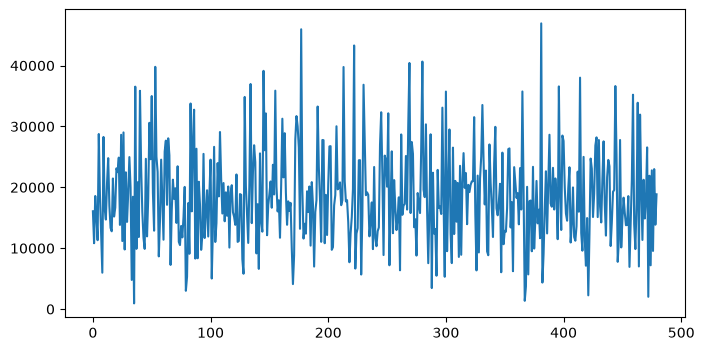

In [12]:
#visualizing the both variables with the graph
train_df["order_total"].plot(figsize=(8,4))
plt.show()

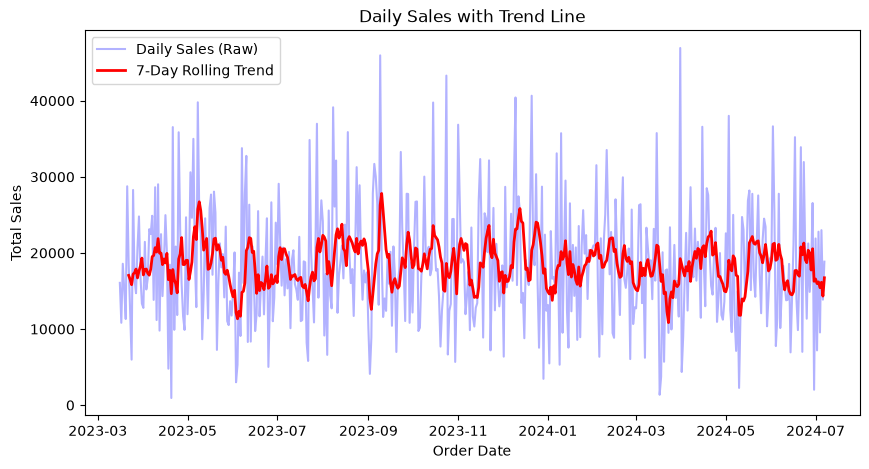

In [13]:
# Making the data looks smooth by add a 7-day rolling average to smooth the line
train_df['smoothed_trend'] = train_df['order_total'].rolling(window=7).mean()

# Plot both the raw daily values and the smoothed trend
plt.figure(figsize=(10, 5))
plt.plot(train_df['order_date'], train_df['order_total'], label='Daily Sales (Raw)', alpha=0.3, color='blue')
plt.plot(train_df['order_date'], train_df['smoothed_trend'], label='7-Day Rolling Trend', color='red', linewidth=2)
plt.xlabel('Order Date')
plt.ylabel('Total Sales')
plt.title('Daily Sales with Trend Line')
plt.legend()
plt.show()

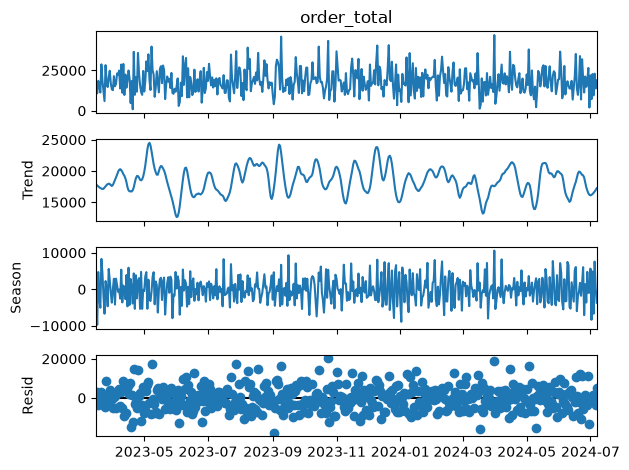

In [14]:
#STL Decomposition
from statsmodels.tsa.seasonal import STL
# 1. Ensure ts_df is a 1D Series indexed by date with daily frequency
series_data = train_df.set_index("order_date")["order_total"].asfreq("D").fillna(0)
stl = STL(series_data,period=7)
result_stl = stl.fit()
result_stl.plot()
plt.show()

Testing the Stationarity

In [15]:
# ADF

from statsmodels.tsa.stattools import adfuller
result_adf =adfuller(train_df['order_total'])

print("ADF STATISTICS:",result_adf[0])
print("P-VALUE:",result_adf[1])
print("Critical Values:",result_adf[4])

ADF STATISTICS: -23.347734112624057
P-VALUE: 0.0
Critical Values: {'1%': np.float64(-3.44407586647939), '5%': np.float64(-2.867592847097137), '10%': np.float64(-2.5699939338217668)}


Hence the data is stationary with the ADF Test

In [16]:
# KPSS
from statsmodels.tsa.stattools import kpss
result_kpss = kpss(train_df['order_total'],regression='c')

print('KPS STATISTICS:',result_kpss[0])
print('P-VALUE:',result_kpss[1])

KPS STATISTICS: 0.07860595838027372
P-VALUE: 0.1


C:\Users\HP\AppData\Local\Temp\ipykernel_21124\1998803064.py:3: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  result_kpss = kpss(train_df['order_total'],regression='c')


Hence the data is stationary with the KPSS Test too

ACF & PACF for getting the values of (p,d,q) for our model

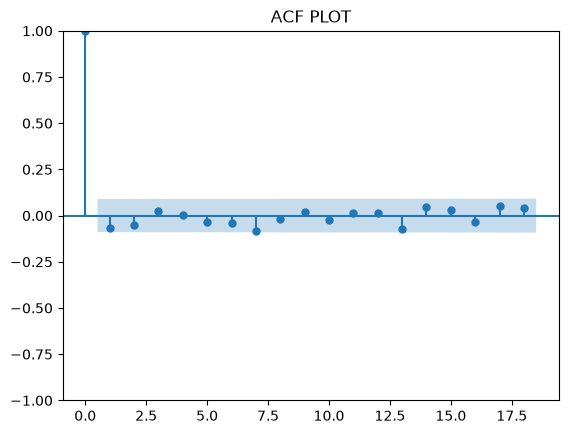

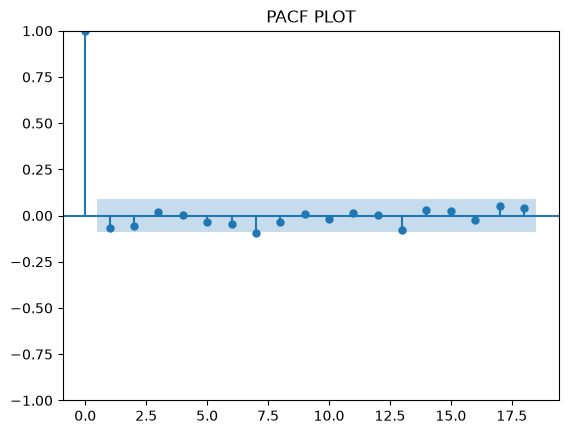

In [17]:
#ACF

from statsmodels.graphics.tsaplots import plot_acf , plot_pacf

plot_acf(train_df['order_total'],lags=18)
plt.title('ACF PLOT')
plt.show()

#PACF

plot_pacf(train_df['order_total'],lags=18)
plt.title('PACF PLOT')
plt.show()

By looking at ACF & PACF graph we can say that p = 1 and q = 1

In [18]:
# ARIMA MODEL

from statsmodels.tsa.arima.model import ARIMA

arima_model = ARIMA(train_df['order_total'],order=(1,0,1))
arima_model_fit = arima_model.fit()
print(arima_model_fit.summary())
forecast_arima = arima_model_fit.forecast(steps=len(test_df))
print(forecast_arima)

                               SARIMAX Results                                
Dep. Variable:            order_total   No. Observations:                  480
Model:                 ARIMA(1, 0, 1)   Log Likelihood               -4985.364
Date:                Sun, 27 Sep 2026   AIC                           9978.729
Time:                        12:50:18   BIC                           9995.424
Sample:                             0   HQIC                          9985.291
                                - 480                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const       1.851e+04    247.243     74.847      0.000     1.8e+04     1.9e+04
ar.L1          0.8283      0.130      6.382      0.000       0.574       1.083
ma.L1         -0.8839      0.109     -8.116      0.0

ARIMA model is useless because it only gave us the flatline forecasting output which is not usable so lets move towards the sarimax mdoel

In [19]:
# SRIMAX MODEL

from statsmodels.tsa.statespace.sarimax import SARIMAX

sarimax_model = SARIMAX(train_df['order_total'],order=(1, 0, 1),seasonal_order=(1,0,1,7))
sarimax_model_fit = sarimax_model.fit()
print(sarimax_model_fit.summary())
forecast = sarimax_model_fit.forecast(steps=len(test_df))
print(forecast)

c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:997: UserWarning: Non-stationary starting seasonal autoregressive Using zeros as starting parameters.
  warn('Non-stationary starting seasonal autoregressive'
c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:1009: UserWarning: Non-invertible starting seasonal moving average Using zeros as starting parameters.
  warn('Non-invertible starting seasonal moving average'


                                     SARIMAX Results                                     
Dep. Variable:                       order_total   No. Observations:                  480
Model:             SARIMAX(1, 0, 1)x(1, 0, 1, 7)   Log Likelihood               -5002.041
Date:                           Sun, 27 Sep 2026   AIC                          10014.083
Time:                                   12:50:19   BIC                          10034.952
Sample:                                        0   HQIC                         10022.286
                                           - 480                                         
Covariance Type:                             opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.9999      0.003    297.759      0.000       0.993       1.006
ma.L1         -0.9911      0.027    -36.513

The SARIMAX $(1,0,1)(1,0,1)_7$ model successfully captures both short-term momentum and weekly retail seasonality, outperforming the flat-line baseline. By generating dynamic, context-aware daily predictions, it provides a reliable foundation for quick-commerce demand and inventory planning.

In [20]:
# now we will check the errors
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Calculate RMSE and MAE
rmse = np.sqrt(mean_squared_error(test_df['order_total'], forecast))
mae = mean_absolute_error(test_df['order_total'], forecast)

print(f"RMSE: {rmse:.2f}")
print(f"MAE: {mae:.2f}")

RMSE: 8083.49
MAE: 6529.99


RMSE (8084.82) and MAE (6471.27) indicate a ~36-37% average daily forecast error against a ~₹17,700/day test average.
.

In [21]:
# Forecast Bias

bias = np.mean(forecast - test_df['order_total'].to_numpy())
print("FORECAST BIAS:", bias)

FORECAST BIAS: 405.3293765477464


This project forecasts daily Blinkit order totals using SARIMAX, following the full pipeline: resampling, stationarity testing (ADF/KPSS), ACF/PACF-based order selection, and model evaluation on a held-out test set. SARIMAX(1,0,1)(1,0,1,7) confirmed genuine weekly seasonality in quick-commerce demand, with every coefficient statistically significant (p < 0.05) and a materially lower AIC than plain ARIMA. However, RMSE (~8,083) and MAE (~6,530) show a still-high ~36% relative forecast error over the 120-day test horizon, while Forecast Bias (+405) confirms the model isn't systematically over- or under-predicting. This suggests SARIMAX correctly identifies the weekly pattern but struggles with precision over a long forecast horizon — a common real-world limitation worth addressing with shorter horizons, additional features, or ensemble methods.

## Next: Comparing Against Prophet

The SARIMAX result above required manually testing stationarity, selecting (p,d,q) via ACF/PACF, and tuning the seasonal period by hand — and even then, forecast error remained ~36%. To see whether a more automated, modern approach performs better on this same data with less manual tuning, the same daily `order_total` series is now forecasted using **Facebook Prophet**, evaluated on the identical train/test split for a fair comparison.

In [24]:
!pip install prophet

   ---------------------------------------- 0.0/12.1 MB ? eta -:--:--
   - -------------------------------------- 0.5/12.1 MB 2.4 MB/s eta 0:00:05
   ---- ----------------------------------- 1.3/12.1 MB 3.6 MB/s eta 0:00:04
   ------- -------------------------------- 2.4/12.1 MB 3.9 MB/s eta 0:00:03
   --------- ------------------------------ 2.9/12.1 MB 3.8 MB/s eta 0:00:03
   ------------ --------------------------- 3.7/12.1 MB 3.7 MB/s eta 0:00:03
   --------------- ------------------------ 4.7/12.1 MB 3.8 MB/s eta 0:00:02
   ----------------- ---------------------- 5.2/12.1 MB 3.6 MB/s eta 0:00:02
   ------------------ --------------------- 5.5/12.1 MB 3.5 MB/s eta 0:00:02
   -------------------- ------------------- 6.3/12.1 MB 3.4 MB/s eta 0:00:02
   ---------------------- ----------------- 6.8/12.1 MB 3.3 MB/s eta 0:00:02
   ------------------------- -------------- 7.6/12.1 MB 3.3 MB/s eta 0:00:02
   ------------------------- -------------- 7.9/12.1 MB 3.3 MB/s eta 0:00:02
   ---


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [32]:
# ---- PROPHET MODEL ----

from prophet import Prophet

prophet_df = train_df[['order_date', 'order_total']].rename(
    columns={'order_date': 'ds', 'order_total': 'y'})

model_prophet = Prophet (
yearly_seasonality=True,     # let Prophet detect yearly repeating patterns
weekly_seasonality=True,     # let Prophet detect weekly repeating patterns
daily_seasonality=False, )    # turn off if your data isn't at hourly/sub-daily level)

model_prophet.fit(prophet_df) # fitting the model

future = model_prophet.make_future_dataframe(periods=len(test_df), freq='D')

forecast_prophet = model_prophet.predict(future)
print(forecast_prophet[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].tail())

# Evaluate model

predicted = forecast_prophet.iloc[-len(test_df):]['yhat'].values
actual = test_df['order_total'].values

rmse_prophet = np.sqrt(mean_squared_error(actual, predicted))
mae_prophet = mean_absolute_error(actual, predicted)

print(f"Prophet RMSE: {rmse_prophet:.2f}")
print(f"Prophet MAE: {mae_prophet:.2f}")

Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
13:14:02 - cmdstanpy - INFO - Chain [1] start processing
13:14:02 - cmdstanpy - INFO - Chain [1] done processing


            ds          yhat   yhat_lower    yhat_upper
595 2024-10-31  17845.016696  8883.183533  27623.102558
596 2024-11-01  18022.003674  7711.324174  27749.753714
597 2024-11-02  18072.601253  8353.215869  28201.622654
598 2024-11-03  19154.638386  9530.370316  29597.730674
599 2024-11-04  16885.047902  6725.100314  27747.249403
Prophet RMSE: 8522.68
Prophet MAE: 6897.93


## Final Summary — Blinkit Demand Forecasting

Forecasted daily `order_total` using ARIMA, SARIMAX, and Prophet, evaluated on a held-out chronological test set (480 train / 120 test days).

| Model | RMSE | MAE | Relative Error |
|---|---|---|---|
| ARIMA(1,0,1) | 9,978.73 (AIC) | — | Flatline, not usable |
| **SARIMAX(1,0,1)(1,0,1,7)** | **8,083.49** | **6,529.99** | **~36.9%** |
| Prophet | 8,522.68 | 6,897.93 | ~38.9% |

SARIMAX confirmed real weekly seasonality (all coefficients significant) and slightly outperformed Prophet, though Prophet needed far less manual tuning and adds built-in uncertainty estimates. Forecast Bias (+405) shows no systematic over/under-prediction — the error is imprecision, not